# Proyecto Integrado 2 — Predicción de recuperación de oro

La empresa Zyfra desarrolla soluciones de eficiencia para la industria pesada.

El objetivo de este proyecto es construir un modelo de machine learning capaz de predecir la recuperación de oro durante distintas etapas del proceso de extracción y purificación.

El modelo deberá predecir dos variables objetivo:

- `rougher.output.recovery`: recuperación del concentrado rougher después de la flotación.
- `final.output.recovery`: recuperación final del concentrado después de las etapas de purificación.

La calidad de los modelos se evaluará mediante la métrica **sMAPE**, y la selección final se basará en una combinación ponderada de los errores correspondientes a ambos objetivos.

El proyecto se desarrollará en tres etapas principales:

1. Preparación y validación de los datos.
2. Análisis exploratorio del proceso de concentración de metales.
3. Desarrollo, comparación y evaluación de modelos de machine learning.

## 1. Preparación de los datos

Primero se importarán las librerías necesarias y se cargarán los tres conjuntos de datos disponibles:

- `gold_recovery_train.csv`: conjunto de entrenamiento.
- `gold_recovery_test.csv`: conjunto de prueba.
- `gold_recovery_full.csv`: conjunto completo con todas las características y objetivos.

Se realizará una inspección inicial de la estructura, tipos de datos, valores ausentes y diferencias entre los conjuntos.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, make_scorer
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor

### 1.1 Carga de los datos

Se cargan los tres archivos disponibles para el proyecto.

El conjunto de entrenamiento contiene las observaciones utilizadas para entrenar los modelos.

El conjunto de prueba contiene observaciones sin las variables objetivo y se utilizará para la evaluación final.

El conjunto completo contiene todas las características y objetivos, y permitirá recuperar posteriormente las variables objetivo correspondientes al conjunto de prueba.

In [4]:
train = pd.read_csv('gold_recovery_train.csv')
test = pd.read_csv('gold_recovery_test.csv')
full = pd.read_csv('gold_recovery_full.csv')

In [5]:
print('Tamaño de train:', train.shape)
print('Tamaño de test:', test.shape)
print('Tamaño de full:', full.shape)

Tamaño de train: (16860, 87)
Tamaño de test: (5856, 53)
Tamaño de full: (22716, 87)


### 1.2 Inspección inicial de los conjuntos de datos

A continuación se revisará la estructura de los tres conjuntos de datos para conocer:

- el número de filas y columnas;
- las primeras observaciones;
- los tipos de datos;
- la cantidad de valores ausentes;
- las posibles diferencias entre las columnas disponibles en entrenamiento y prueba.

In [6]:
print('TRAIN')
display(train.head())

print('\nTEST')
display(test.head())

print('\nFULL')
display(full.head())

TRAIN


,date,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-01-15 00:00:00,6.055403,9.889648,5.507324,42.192020,70.541216,10.411962,0.895447,16.904297,2.143149,...,14.016835,-502.488007,12.099931,-504.715942,9.925633,-498.310211,8.079666,-500.470978,14.151341,-605.841980
1,2016-01-15 01:00:00,6.029369,9.968944,5.257781,42.701629,69.266198,10.462676,0.927452,16.634514,2.224930,...,13.992281,-505.503262,11.950531,-501.331529,10.039245,-500.169983,7.984757,-500.582168,13.998353,-599.787184
2,2016-01-15 02:00:00,6.055926,10.213995,5.383759,42.657501,68.116445,10.507046,0.953716,16.208849,2.257889,...,14.015015,-502.520901,11.912783,-501.133383,10.070913,-500.129135,8.013877,-500.517572,14.028663,-601.427363
3,2016-01-15 03:00:00,6.047977,9.977019,4.858634,42.689819,68.347543,10.422762,0.883763,16.532835,2.146849,...,14.036510,-500.857308,11.999550,-501.193686,9.970366,-499.201640,7.977324,-500.255908,14.005551,-599.996129
4,2016-01-15 04:00:00,6.148599,10.142511,4.939416,42.774141,66.927016,10.360302,0.792826,16.525686,2.055292,...,14.027298,-499.838632,11.953070,-501.053894,9.925709,-501.686727,7.894242,-500.356035,13.996647,-601.496691



TEST


,date,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-09-01 00:59:59,210.800909,14.993118,8.080000,1.005021,1398.981301,-500.225577,1399.144926,-499.919735,1400.102998,...,12.023554,-497.795834,8.016656,-501.289139,7.946562,-432.317850,4.872511,-500.037437,26.705889,-499.709414
1,2016-09-01 01:59:59,215.392455,14.987471,8.080000,0.990469,1398.777912,-500.057435,1398.055362,-499.778182,1396.151033,...,12.058140,-498.695773,8.130979,-499.634209,7.958270,-525.839648,4.878850,-500.162375,25.019940,-499.819438
2,2016-09-01 02:59:59,215.259946,12.884934,7.786667,0.996043,1398.493666,-500.868360,1398.860436,-499.764529,1398.075709,...,11.962366,-498.767484,8.096893,-500.827423,8.071056,-500.801673,4.905125,-499.828510,24.994862,-500.622559
3,2016-09-01 03:59:59,215.336236,12.006805,7.640000,0.863514,1399.618111,-498.863574,1397.440120,-499.211024,1400.129303,...,12.033091,-498.350935,8.074946,-499.474407,7.897085,-500.868509,4.931400,-499.963623,24.948919,-498.709987
4,2016-09-01 04:59:59,199.099327,10.682530,7.530000,0.805575,1401.268123,-500.808305,1398.128818,-499.504543,1402.172226,...,12.025367,-500.786497,8.054678,-500.397500,8.107890,-509.526725,4.957674,-500.360026,25.003331,-500.856333



FULL


,date,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,...,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-01-15 00:00:00,6.055403,9.889648,5.507324,42.192020,70.541216,10.411962,0.895447,16.904297,2.143149,...,14.016835,-502.488007,12.099931,-504.715942,9.925633,-498.310211,8.079666,-500.470978,14.151341,-605.841980
1,2016-01-15 01:00:00,6.029369,9.968944,5.257781,42.701629,69.266198,10.462676,0.927452,16.634514,2.224930,...,13.992281,-505.503262,11.950531,-501.331529,10.039245,-500.169983,7.984757,-500.582168,13.998353,-599.787184
2,2016-01-15 02:00:00,6.055926,10.213995,5.383759,42.657501,68.116445,10.507046,0.953716,16.208849,2.257889,...,14.015015,-502.520901,11.912783,-501.133383,10.070913,-500.129135,8.013877,-500.517572,14.028663,-601.427363
3,2016-01-15 03:00:00,6.047977,9.977019,4.858634,42.689819,68.347543,10.422762,0.883763,16.532835,2.146849,...,14.036510,-500.857308,11.999550,-501.193686,9.970366,-499.201640,7.977324,-500.255908,14.005551,-599.996129
4,2016-01-15 04:00:00,6.148599,10.142511,4.939416,42.774141,66.927016,10.360302,0.792826,16.525686,2.055292,...,14.027298,-499.838632,11.953070,-501.053894,9.925709,-501.686727,7.894242,-500.356035,13.996647,-601.496691


In [7]:
print('TRAIN')
train.info()

print('\nTEST')
test.info()

print('\nFULL')
full.info()

TRAIN
<class 'pandas.DataFrame'>
RangeIndex: 16860 entries, 0 to 16859
Data columns (total 87 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   date                                                16860 non-null  str    
 1   final.output.concentrate_ag                         16788 non-null  float64
 2   final.output.concentrate_pb                         16788 non-null  float64
 3   final.output.concentrate_sol                        16490 non-null  float64
 4   final.output.concentrate_au                         16789 non-null  float64
 5   final.output.recovery                               15339 non-null  float64
 6   final.output.tail_ag                                16794 non-null  float64
 7   final.output.tail_pb                                16677 non-null  float64
 8   final.output.tail_sol                               16715 non-null  float64
 9   

In [8]:
print('Valores ausentes en TRAIN:', train.isna().sum().sum())
print('Valores ausentes en TEST:', test.isna().sum().sum())
print('Valores ausentes en FULL:', full.isna().sum().sum())

Valores ausentes en TRAIN: 30320
Valores ausentes en TEST: 2360
Valores ausentes en FULL: 36587


In [9]:
print('\nColumnas con más valores ausentes en TRAIN:')
display(train.isna().sum().sort_values(ascending=False).head(15))

print('\nColumnas con más valores ausentes en TEST:')
display(test.isna().sum().sort_values(ascending=False).head(15))

print('\nColumnas con más valores ausentes en FULL:')
display(full.isna().sum().sort_values(ascending=False).head(15))


Columnas con más valores ausentes en TRAIN:


rougher.output.recovery                   2573
rougher.output.tail_ag                    2250
rougher.output.tail_au                    2249
rougher.output.tail_sol                   2249
secondary_cleaner.output.tail_sol         1986
rougher.input.floatbank11_xanthate        1904
final.output.recovery                     1521
primary_cleaner.input.sulfate             1307
primary_cleaner.input.depressant          1262
rougher.calculation.au_pb_ratio           1242
rougher.input.floatbank10_sulfate         1044
primary_cleaner.input.xanthate             985
primary_cleaner.output.concentrate_sol     636
rougher.input.floatbank11_sulfate          623
rougher.state.floatbank10_e_air            603
dtype: int64


Columnas con más valores ausentes en TEST:


rougher.input.floatbank11_xanthate          353
primary_cleaner.input.sulfate               302
primary_cleaner.input.depressant            284
rougher.input.floatbank10_sulfate           257
primary_cleaner.input.xanthate              166
rougher.input.floatbank10_xanthate          123
rougher.input.feed_sol                       67
rougher.input.floatbank11_sulfate            55
rougher.input.feed_rate                      40
secondary_cleaner.state.floatbank3_a_air     34
secondary_cleaner.state.floatbank2_b_air     23
rougher.input.feed_size                      22
secondary_cleaner.state.floatbank2_a_air     20
rougher.state.floatbank10_a_air              17
rougher.state.floatbank10_c_air              17
dtype: int64


Columnas con más valores ausentes en FULL:


rougher.output.recovery                   3119
rougher.output.tail_ag                    2737
rougher.output.tail_au                    2736
rougher.output.tail_sol                   2736
rougher.input.floatbank11_xanthate        2257
secondary_cleaner.output.tail_sol         2215
final.output.recovery                     1963
rougher.calculation.au_pb_ratio           1627
primary_cleaner.input.sulfate             1609
primary_cleaner.input.depressant          1546
rougher.input.floatbank10_sulfate         1301
primary_cleaner.input.xanthate            1151
primary_cleaner.output.concentrate_sol     798
rougher.input.floatbank11_sulfate          678
rougher.state.floatbank10_e_air            620
dtype: int64

### Conclusiones de la inspección inicial

Los conjuntos de datos presentan tamaños diferentes:

- El conjunto de entrenamiento contiene 16,860 observaciones y 87 columnas.
- El conjunto de prueba contiene 5,856 observaciones y 53 columnas.
- El conjunto completo contiene 22,716 observaciones y 87 columnas.

El conjunto de prueba tiene menos características que los conjuntos de entrenamiento y completo. Esto es consistente con la descripción del proyecto, ya que algunas variables se calculan o registran después del proceso y, por tanto, no están disponibles al momento de realizar una predicción.

También se observan valores ausentes en los tres conjuntos de datos. El conjunto de entrenamiento contiene 30,320 valores ausentes, el conjunto de prueba 2,360 y el conjunto completo 36,587.

La columna `date` es de tipo texto y las demás variables son numéricas.

Antes de entrenar los modelos será necesario analizar las columnas ausentes en el conjunto de prueba y definir una estrategia de preprocesamiento para los valores faltantes.

### 1.3 Verificación del cálculo de recuperación rougher

El proyecto solicita comprobar si la variable `rougher.output.recovery` fue calculada correctamente.

La recuperación se calculará utilizando:

- `rougher.output.concentrate_au` como concentración de oro en el concentrado;
- `rougher.input.feed_au` como concentración de oro en la alimentación;
- `rougher.output.tail_au` como concentración de oro en las colas.

Después se comparará el valor calculado con `rougher.output.recovery` mediante el error absoluto medio (MAE).

In [10]:
C = train['rougher.output.concentrate_au']
F = train['rougher.input.feed_au']
T = train['rougher.output.tail_au']

recovery_calculated = (
    C * (F - T) /
    (F * (C - T))
) * 100

recovery_comparison = pd.DataFrame({
    'calculated': recovery_calculated,
    'actual': train['rougher.output.recovery']
}).dropna()

mae_recovery = mean_absolute_error(
    recovery_comparison['actual'],
    recovery_comparison['calculated']
)

print('MAE del cálculo de recovery:', mae_recovery)

MAE del cálculo de recovery: 9.303415616264301e-15


### Conclusión sobre el cálculo de recuperación

El MAE entre la recuperación calculada manualmente y la columna `rougher.output.recovery` es aproximadamente **9.30 × 10⁻¹⁵**.

Este valor es prácticamente cero y puede atribuirse únicamente a pequeñas diferencias de precisión numérica en los cálculos.

Por lo tanto, se confirma que la variable `rougher.output.recovery` fue calculada correctamente.

### 1.4 Características no disponibles en el conjunto de prueba

El conjunto de prueba contiene menos columnas que el conjunto de entrenamiento.

Esto ocurre porque algunas características corresponden a resultados del proceso, cálculos posteriores o mediciones que todavía no estarían disponibles en el momento de realizar una predicción.

A continuación se identificarán las columnas presentes en el conjunto de entrenamiento pero ausentes en el conjunto de prueba.

In [11]:
missing_in_test = [
    column
    for column in train.columns
    if column not in test.columns
]

print('Número de columnas ausentes en TEST:', len(missing_in_test))

for column in missing_in_test:
    print(column)

print('\nTipos de las columnas ausentes:')

display(
    train[missing_in_test].dtypes
)

Número de columnas ausentes en TEST: 34
final.output.concentrate_ag
final.output.concentrate_pb
final.output.concentrate_sol
final.output.concentrate_au
final.output.recovery
final.output.tail_ag
final.output.tail_pb
final.output.tail_sol
final.output.tail_au
primary_cleaner.output.concentrate_ag
primary_cleaner.output.concentrate_pb
primary_cleaner.output.concentrate_sol
primary_cleaner.output.concentrate_au
primary_cleaner.output.tail_ag
primary_cleaner.output.tail_pb
primary_cleaner.output.tail_sol
primary_cleaner.output.tail_au
rougher.calculation.sulfate_to_au_concentrate
rougher.calculation.floatbank10_sulfate_to_au_feed
rougher.calculation.floatbank11_sulfate_to_au_feed
rougher.calculation.au_pb_ratio
rougher.output.concentrate_ag
rougher.output.concentrate_pb
rougher.output.concentrate_sol
rougher.output.concentrate_au
rougher.output.recovery
rougher.output.tail_ag
rougher.output.tail_pb
rougher.output.tail_sol
rougher.output.tail_au
secondary_cleaner.output.tail_ag
secondary_c

final.output.concentrate_ag                           float64
final.output.concentrate_pb                           float64
final.output.concentrate_sol                          float64
final.output.concentrate_au                           float64
final.output.recovery                                 float64
final.output.tail_ag                                  float64
final.output.tail_pb                                  float64
final.output.tail_sol                                 float64
final.output.tail_au                                  float64
primary_cleaner.output.concentrate_ag                 float64
primary_cleaner.output.concentrate_pb                 float64
primary_cleaner.output.concentrate_sol                float64
primary_cleaner.output.concentrate_au                 float64
primary_cleaner.output.tail_ag                        float64
primary_cleaner.output.tail_pb                        float64
primary_cleaner.output.tail_sol                       float64
primary_

### Conclusión sobre las características ausentes en el conjunto de prueba

Se identificaron **34 columnas** presentes en el conjunto de entrenamiento pero ausentes en el conjunto de prueba.

Todas estas variables son numéricas (`float64`).

Al analizar sus nombres se observa que:

- **30 columnas corresponden a parámetros de tipo `output`**, es decir, resultados obtenidos después de distintas etapas del proceso.
- **4 columnas corresponden a parámetros de tipo `calculation`**, es decir, variables calculadas posteriormente.
- Entre las variables ausentes se encuentran también los dos objetivos del proyecto:
  - `rougher.output.recovery`
  - `final.output.recovery`

Estas características no pueden utilizarse como variables predictoras del modelo, ya que no estarán disponibles en el momento real de realizar una predicción.

Por lo tanto, los modelos deberán entrenarse únicamente con las características que también estén disponibles en el conjunto de prueba.

### 1.5 Preprocesamiento de los datos

Antes de continuar con el análisis y el entrenamiento de los modelos, es necesario preparar los datos.

Se realizarán las siguientes acciones:

1. Utilizar `date` para relacionar las observaciones del conjunto de prueba con el conjunto completo y recuperar las variables objetivo.
2. Trabajar únicamente con características disponibles tanto en entrenamiento como en prueba.
3. Tratar los valores ausentes teniendo en cuenta que las observaciones cercanas en el tiempo suelen presentar valores similares.
4. Eliminar posteriormente las anomalías que se identifiquen durante el análisis de concentraciones.

In [12]:
test = test.merge(
    full[['date', 'rougher.output.recovery', 'final.output.recovery']],
    on='date',how='left')

print('Tamaño de TEST después de agregar los objetivos:', test.shape)

print(
    'Valores ausentes en rougher.output.recovery:',
    test['rougher.output.recovery'].isna().sum()
)

print(
    'Valores ausentes en final.output.recovery:',
    test['final.output.recovery'].isna().sum()
)

Tamaño de TEST después de agregar los objetivos: (5856, 55)
Valores ausentes en rougher.output.recovery: 546
Valores ausentes en final.output.recovery: 442


### Tratamiento de valores ausentes

Los valores ausentes requieren tratamientos diferentes dependiendo de si pertenecen a las variables objetivo o a las características predictoras.

Las variables objetivo representan las respuestas reales que el modelo debe aprender o utilizar para evaluar sus predicciones. Por esta razón, no se imputarán valores artificiales en los objetivos. Las observaciones que no dispongan de ambos objetivos serán eliminadas de los conjuntos correspondientes.

Para las características predictoras se aprovechará que los datos están ordenados temporalmente y que, según la descripción del proyecto, los parámetros cercanos en el tiempo suelen ser similares.

Por lo tanto, los valores ausentes de las características se rellenarán principalmente utilizando el último valor conocido (`forward fill`). Los posibles valores que permanezcan ausentes posteriormente se tratarán utilizando estadísticas calculadas a partir del conjunto de entrenamiento.

In [13]:
targets = [
    'rougher.output.recovery',
    'final.output.recovery'
]

train_clean = train.dropna(subset=targets).copy()
test_clean = test.dropna(subset=targets).copy()

print('TRAIN antes:', train.shape)
print('TRAIN después:', train_clean.shape)

print('\nTEST antes:', test.shape)
print('TEST después:', test_clean.shape)

TRAIN antes: (16860, 87)
TRAIN después: (14149, 87)

TEST antes: (5856, 55)
TEST después: (5290, 55)


In [14]:
feature_columns = [
    column
    for column in test.columns
    if column not in ['date'] + targets
]

print('Número de características disponibles para el modelo:', len(feature_columns))

print('\nPrimeras características:')
for column in feature_columns[:10]:
    print(column)

Número de características disponibles para el modelo: 52

Primeras características:
primary_cleaner.input.sulfate
primary_cleaner.input.depressant
primary_cleaner.input.feed_size
primary_cleaner.input.xanthate
primary_cleaner.state.floatbank8_a_air
primary_cleaner.state.floatbank8_a_level
primary_cleaner.state.floatbank8_b_air
primary_cleaner.state.floatbank8_b_level
primary_cleaner.state.floatbank8_c_air
primary_cleaner.state.floatbank8_c_level


### Relleno de valores ausentes en las características

Las características contienen valores ausentes que deben tratarse antes de entrenar los modelos.

Debido a que las observaciones están ordenadas temporalmente y los parámetros cercanos en el tiempo suelen ser similares, se utilizará `forward fill` para completar los valores faltantes con el último valor conocido.

Si después de este procedimiento permanecen valores ausentes, se utilizará la mediana calculada únicamente a partir del conjunto de entrenamiento.

De esta manera se evita utilizar información del conjunto de prueba para preparar los datos de entrenamiento.

## 2. Análisis de los datos

En esta sección se analizarán algunas propiedades importantes del proceso de extracción y purificación del oro.

Se estudiarán:

1. Los cambios en la concentración de los metales `Au`, `Ag` y `Pb` durante las diferentes etapas de purificación.
2. Las distribuciones del tamaño de las partículas de alimentación en los conjuntos de entrenamiento y prueba.
3. Las concentraciones totales de las sustancias en las principales etapas del proceso para detectar posibles valores anómalos.

### 2.1 Evolución de la concentración de metales

Se analizará cómo cambia la concentración promedio de tres metales durante el proceso:

- `Au`: oro.
- `Ag`: plata.
- `Pb`: plomo.

Se compararán cuatro puntos del proceso:

1. Alimentación inicial (`rougher.input.feed`).
2. Concentrado después de la flotación (`rougher.output.concentrate`).
3. Concentrado después de la primera etapa de purificación (`primary_cleaner.output.concentrate`).
4. Concentrado final (`final.output.concentrate`).

Esto permitirá observar cómo el proceso de enriquecimiento modifica la concentración de cada metal.

In [15]:
metals = ['au', 'ag', 'pb']

stages = {
    'Alimentación': 'rougher.input.feed_',
    'Rougher': 'rougher.output.concentrate_',
    'Primera limpieza': 'primary_cleaner.output.concentrate_',
    'Final': 'final.output.concentrate_'
}

metal_concentrations = pd.DataFrame()

for metal in metals:
    for stage_name, prefix in stages.items():
        column = prefix + metal
        
        metal_concentrations.loc[metal.upper(), stage_name] = (
            train_clean[column].mean()
        )

display(metal_concentrations.round(2))

,Alimentación,Rougher,Primera limpieza,Final
AU,7.87,19.44,32.39,44.00
AG,8.58,11.78,8.20,5.14
PB,3.52,7.66,9.59,10.13


### Conclusión sobre la concentración de metales

La concentración de oro (`Au`) aumenta de manera considerable a lo largo del proceso, pasando de aproximadamente **7.87** en la alimentación inicial a **44.00** en el concentrado final.

Esto indica que el proceso de flotación y las etapas de purificación cumplen su objetivo principal de enriquecer progresivamente el concentrado en oro.

La concentración de plata (`Ag`) aumenta inicialmente durante la etapa rougher, pero posteriormente disminuye durante las etapas de purificación, pasando de 11.78 después de la flotación a 5.14 en el concentrado final.

Por otro lado, la concentración de plomo (`Pb`) aumenta progresivamente, desde aproximadamente 3.52 en la alimentación inicial hasta 10.13 en el concentrado final.

En conjunto, los resultados muestran que el proceso incrementa significativamente la proporción de oro en el producto final, mientras que los demás metales presentan comportamientos diferentes durante las etapas de purificación.

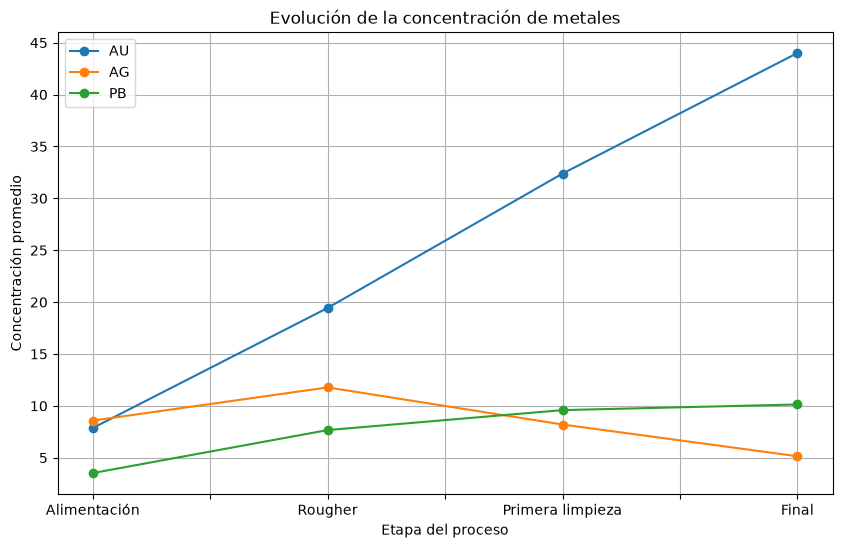

In [16]:
metal_concentrations.T.plot(
    kind='line',
    marker='o',
    figsize=(10, 6)
)

plt.title('Evolución de la concentración de metales')
plt.xlabel('Etapa del proceso')
plt.ylabel('Concentración promedio')
plt.grid(True)
plt.show()

### 2.2 Distribución del tamaño de las partículas de alimentación

El siguiente paso consiste en comparar la distribución del tamaño de las partículas de alimentación entre los conjuntos de entrenamiento y prueba.

Esta comparación es importante porque, si ambas distribuciones fueran muy diferentes, el conjunto de prueba no representaría adecuadamente los datos utilizados para entrenar el modelo y la evaluación podría ser poco fiable.

Se analizará la variable `rougher.input.feed_size`, que representa el tamaño de las partículas de la alimentación antes del proceso de flotación.

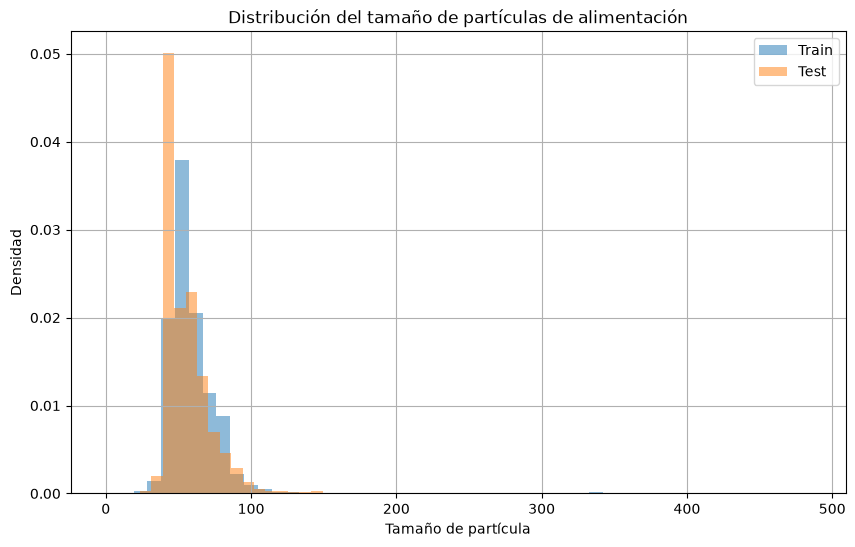

In [17]:
plt.figure(figsize=(10, 6))

train_clean['rougher.input.feed_size'].plot(
    kind='hist',
    bins=50,
    density=True,
    alpha=0.5,
    label='Train'
)

test_clean['rougher.input.feed_size'].plot(
    kind='hist',
    bins=50,
    density=True,
    alpha=0.5,
    label='Test'
)

plt.title('Distribución del tamaño de partículas de alimentación')
plt.xlabel('Tamaño de partícula')
plt.ylabel('Densidad')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
feed_size_comparison = pd.DataFrame({
    'Train': train_clean['rougher.input.feed_size'].describe(),
    'Test': test_clean['rougher.input.feed_size'].describe()
})

display(feed_size_comparison.round(2))

,Train,Test
count,14005.00,5289.00
mean,60.11,55.95
std,22.42,19.08
min,9.66,0.05
25%,48.97,43.91
50%,55.37,50.84
75%,66.08,62.43
max,484.97,392.49


### Comparación de las distribuciones de tamaño de partículas

Las distribuciones del tamaño de las partículas de alimentación en los conjuntos de entrenamiento y prueba presentan una forma general similar.

El conjunto de prueba muestra una ligera concentración mayor en tamaños de partícula más pequeños, mientras que el conjunto de entrenamiento presenta una media y una mediana algo superiores.

Los valores centrales son relativamente cercanos:

- Media en entrenamiento: **60.11**
- Media en prueba: **55.95**
- Mediana en entrenamiento: **55.37**
- Mediana en prueba: **50.84**

Los percentiles 25% y 75% también se encuentran en rangos similares.

Aunque existen algunas diferencias y valores extremos en ambos conjuntos, las distribuciones no parecen variar de manera significativa como para invalidar la evaluación del modelo.

Por lo tanto, se considera que los tamaños de partícula de alimentación de entrenamiento y prueba son suficientemente comparables para continuar con el análisis.

### 2.3 Concentraciones totales y detección de anomalías

Ahora se analizará la concentración total de las sustancias principales en tres etapas del proceso:

1. Alimentación inicial (`rougher.input.feed`).
2. Concentrado rougher (`rougher.output.concentrate`).
3. Concentrado final (`final.output.concentrate`).

Para cada etapa se sumarán las concentraciones de:

- oro (`Au`);
- plata (`Ag`);
- plomo (`Pb`);
- sólidos (`Sol`).

El objetivo es detectar valores anormalmente bajos, especialmente concentraciones totales cercanas a cero, ya que podrían representar mediciones incorrectas o condiciones atípicas del proceso.

In [19]:
train_clean = train.dropna(subset=targets).copy()

train_clean['total_feed'] = (
    train_clean['rougher.input.feed_au'] +
    train_clean['rougher.input.feed_ag'] +
    train_clean['rougher.input.feed_pb'] +
    train_clean['rougher.input.feed_sol']
)

train_clean['total_rougher'] = (
    train_clean['rougher.output.concentrate_au'] +
    train_clean['rougher.output.concentrate_ag'] +
    train_clean['rougher.output.concentrate_pb'] +
    train_clean['rougher.output.concentrate_sol']
)

train_clean['total_final'] = (
    train_clean['final.output.concentrate_au'] +
    train_clean['final.output.concentrate_ag'] +
    train_clean['final.output.concentrate_pb'] +
    train_clean['final.output.concentrate_sol']
)

print('Tamaño reconstruido de TRAIN:', train_clean.shape)

Tamaño reconstruido de TRAIN: (14149, 90)


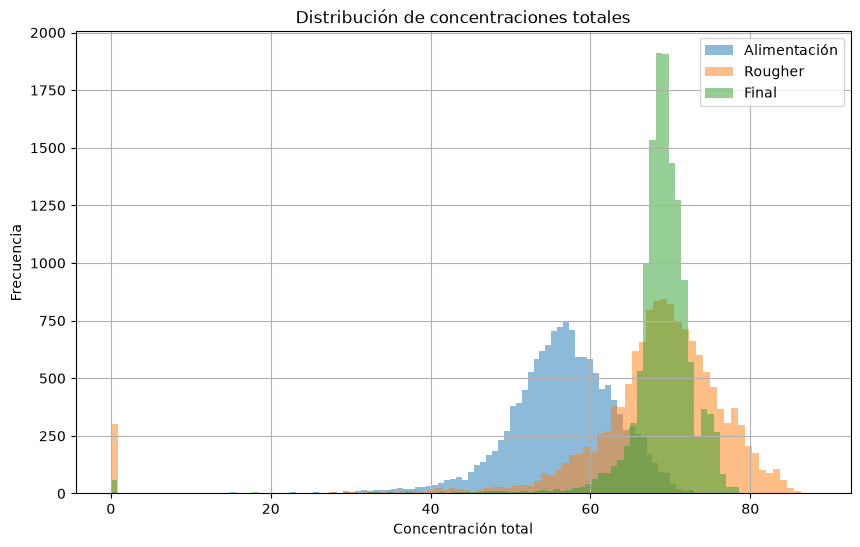

In [20]:
plt.figure(figsize=(10, 6))

train_clean['total_feed'].plot(
    kind='hist',
    bins=100,
    alpha=0.5,
    label='Alimentación'
)

train_clean['total_rougher'].plot(
    kind='hist',
    bins=100,
    alpha=0.5,
    label='Rougher'
)

train_clean['total_final'].plot(
    kind='hist',
    bins=100,
    alpha=0.5,
    label='Final'
)

plt.title('Distribución de concentraciones totales')
plt.xlabel('Concentración total')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(True)
plt.show()

### Análisis de anomalías en las concentraciones totales

Las distribuciones de las concentraciones totales muestran valores concentrados en rangos razonables para la mayoría de las observaciones.

Sin embargo, se observa un grupo anómalo de registros con concentraciones totales iguales a cero, especialmente en el concentrado rougher y, en menor medida, en el concentrado final.

Una concentración total igual a cero para la suma de oro, plata, plomo y sólidos no parece representar una condición normal del proceso y probablemente corresponde a mediciones anómalas o registros inválidos.

Por esta razón, estas observaciones serán eliminadas antes del entrenamiento de los modelos.

In [21]:
zero_feed = (train_clean['total_feed'] == 0).sum()
zero_rougher = (train_clean['total_rougher'] == 0).sum()
zero_final = (train_clean['total_final'] == 0).sum()

anomaly_mask = (
    (train_clean['total_feed'] == 0) |
    (train_clean['total_rougher'] == 0) |
    (train_clean['total_final'] == 0)
)

rows_with_zero = anomaly_mask.sum()

print('Concentración total = 0 en alimentación:', zero_feed)
print('Concentración total = 0 en rougher:', zero_rougher)
print('Concentración total = 0 en final:', zero_final)
print('Filas con al menos una concentración total igual a 0:', rows_with_zero)

Concentración total = 0 en alimentación: 0
Concentración total = 0 en rougher: 297
Concentración total = 0 en final: 58
Filas con al menos una concentración total igual a 0: 354


### Resultado de la detección de anomalías

Se identificaron **354 observaciones** en las que al menos una de las concentraciones totales analizadas era exactamente igual a cero.

En concreto:

- Alimentación inicial: **0** casos.
- Concentrado rougher: **297** casos.
- Concentrado final: **58** casos.

Estas observaciones se consideran anómalas porque una concentración total igual a cero para la suma de oro, plata, plomo y sólidos no parece representar una condición normal del proceso productivo.

A continuación se eliminarán únicamente estas observaciones antes de preparar los datos definitivos para el modelado.

In [22]:
train_clean = train_clean[~anomaly_mask].copy()

print(
    'Tamaño de TRAIN después de eliminar anomalías:',
    train_clean.shape
)

Tamaño de TRAIN después de eliminar anomalías: (13795, 90)


### Conclusión del análisis de concentraciones totales

Después de eliminar las observaciones con concentraciones totales iguales a cero, el conjunto de entrenamiento conserva **13,795 observaciones**.

La eliminación se limitó únicamente a los registros identificados claramente como anómalos, sin utilizar umbrales arbitrarios para eliminar otros valores bajos.

Con esto finaliza el análisis exploratorio de las concentraciones y el conjunto de entrenamiento queda preparado para reconstruir las características y los objetivos que se utilizarán en el modelado.

### Aplicación del criterio de anomalías al conjunto de prueba

El conjunto de prueba no contiene directamente las concentraciones de salida utilizadas para identificar las anomalías.

Sin embargo, estas variables están disponibles en el conjunto completo y pueden relacionarse con las observaciones de prueba mediante `date`.

Se aplicará al conjunto de prueba el mismo criterio utilizado en entrenamiento: eliminar las observaciones en las que la concentración total de la alimentación, del concentrado rougher o del concentrado final sea exactamente igual a cero.

In [23]:
# Columnas de salida necesarias para detectar anomalías en TEST
test_output_columns = [
    'rougher.output.concentrate_au',
    'rougher.output.concentrate_ag',
    'rougher.output.concentrate_pb',
    'rougher.output.concentrate_sol',
    'final.output.concentrate_au',
    'final.output.concentrate_ag',
    'final.output.concentrate_pb',
    'final.output.concentrate_sol'
]

# Recuperamos esas columnas desde FULL usando la fecha
test_anomaly_data = test_clean.merge(
    full[['date'] + test_output_columns],
    on='date',
    how='left'
)

# Calculamos nuevamente las tres concentraciones totales
test_anomaly_data['total_feed'] = (
    test_anomaly_data['rougher.input.feed_au'] +
    test_anomaly_data['rougher.input.feed_ag'] +
    test_anomaly_data['rougher.input.feed_pb'] +
    test_anomaly_data['rougher.input.feed_sol']
)

test_anomaly_data['total_rougher'] = (
    test_anomaly_data['rougher.output.concentrate_au'] +
    test_anomaly_data['rougher.output.concentrate_ag'] +
    test_anomaly_data['rougher.output.concentrate_pb'] +
    test_anomaly_data['rougher.output.concentrate_sol']
)

test_anomaly_data['total_final'] = (
    test_anomaly_data['final.output.concentrate_au'] +
    test_anomaly_data['final.output.concentrate_ag'] +
    test_anomaly_data['final.output.concentrate_pb'] +
    test_anomaly_data['final.output.concentrate_sol']
)

test_anomaly_mask = (
    (test_anomaly_data['total_feed'] == 0) |
    (test_anomaly_data['total_rougher'] == 0) |
    (test_anomaly_data['total_final'] == 0)
)

test_anomaly_dates = test_anomaly_data.loc[
    test_anomaly_mask,
    'date'
]

print('Anomalías detectadas en TEST:', test_anomaly_mask.sum())

test_clean = test_clean[
    ~test_clean['date'].isin(test_anomaly_dates)
].copy()

print('Tamaño de TEST después de eliminar anomalías:', test_clean.shape)

Anomalías detectadas en TEST: 136
Tamaño de TEST después de eliminar anomalías: (5154, 55)


## 3. Construcción y evaluación de modelos

Antes de entrenar los modelos, se reconstruirán las características y las variables objetivo utilizando el conjunto de entrenamiento ya depurado.

Se utilizarán únicamente las características que también están disponibles en el conjunto de prueba.

Además, se volverán a tratar los valores ausentes de las características mediante `forward fill` y, si fuera necesario, mediante las medianas calculadas exclusivamente a partir del conjunto de entrenamiento.

Los dos objetivos que se modelarán por separado son:

- `rougher.output.recovery`
- `final.output.recovery`

In [24]:
features_train = train_clean[feature_columns].copy()
features_test = test_clean[feature_columns].copy()

target_train_rougher = train_clean['rougher.output.recovery'].copy()
target_train_final = train_clean['final.output.recovery'].copy()

target_test_rougher = test_clean['rougher.output.recovery'].copy()
target_test_final = test_clean['final.output.recovery'].copy()

print('FEATURES TRAIN:', features_train.shape)
print('FEATURES TEST:', features_test.shape)

print('TARGET TRAIN ROUGHER:', target_train_rougher.shape)
print('TARGET TRAIN FINAL:', target_train_final.shape)

print('TARGET TEST ROUGHER:', target_test_rougher.shape)
print('TARGET TEST FINAL:', target_test_final.shape)

FEATURES TRAIN: (13795, 52)
FEATURES TEST: (5154, 52)
TARGET TRAIN ROUGHER: (13795,)
TARGET TRAIN FINAL: (13795,)
TARGET TEST ROUGHER: (5154,)
TARGET TEST FINAL: (5154,)


In [25]:
features_train = features_train.ffill()
features_test = features_test.ffill()

train_medians = features_train.median()

features_train = features_train.fillna(train_medians)
features_test = features_test.fillna(train_medians)

print('NaN finales en FEATURES TRAIN:',
      features_train.isna().sum().sum())

print('NaN finales en FEATURES TEST:',
      features_test.isna().sum().sum())

NaN finales en FEATURES TRAIN: 0
NaN finales en FEATURES TEST: 0


### 3.1 Métrica sMAPE

La calidad de los modelos se evaluará mediante la métrica **sMAPE** (Symmetric Mean Absolute Percentage Error).

Esta métrica calcula el error porcentual entre los valores reales y las predicciones teniendo en cuenta la magnitud de ambos valores.

Un valor de sMAPE más pequeño indica mejores predicciones. Un valor de cero representaría predicciones perfectas.

Como el proyecto requiere predecir dos objetivos diferentes, se calculará un sMAPE para la recuperación rougher y otro para la recuperación final.

In [26]:
def smape(y_true, y_pred):
    
    numerator = np.abs(y_true - y_pred)
    
    denominator = (
        np.abs(y_true) + np.abs(y_pred)
    ) / 2
    
    result = np.mean(
        numerator / denominator
    ) * 100
    
    return result

In [27]:
def final_smape(
    y_true_rougher,
    y_pred_rougher,
    y_true_final,
    y_pred_final
):
    
    rougher_smape = smape(
        y_true_rougher,
        y_pred_rougher
    )
    
    final_stage_smape = smape(
        y_true_final,
        y_pred_final
    )
    
    result = (
        0.25 * rougher_smape +
        0.75 * final_stage_smape
    )
    
    return result

### 3.2 Preparación de la métrica para validación cruzada

Para comparar los modelos mediante validación cruzada, la función `sMAPE` debe adaptarse al formato utilizado por `scikit-learn`.

Como en este problema un valor menor de sMAPE representa un mejor resultado, se indicará que la métrica funciona como una pérdida.

Esto permitirá utilizar `cross_val_score()` para evaluar los modelos de forma consistente.

In [28]:
smape_scorer = make_scorer(
    smape,
    greater_is_better=False
)

### 3.3 Comparación de modelos

Se entrenarán y compararán varios modelos de regresión:

- Regresión lineal.
- Árbol de decisión.
- Bosque aleatorio.
- Modelo Dummy como referencia básica.

Cada modelo se evaluará mediante validación cruzada utilizando sMAPE.

Los modelos se evaluarán por separado para los dos objetivos:

- recuperación rougher;
- recuperación final.

Posteriormente se combinarán ambos errores utilizando la fórmula del sMAPE final.

### 3.4 Función para evaluar modelos mediante validación cruzada

Para comparar los modelos de manera uniforme se creará una función que:

1. Evalúe el modelo mediante validación cruzada para `rougher.output.recovery`.
2. Evalúe el mismo modelo para `final.output.recovery`.
3. Convierta los valores negativos devueltos por `scikit-learn` a valores positivos de sMAPE.
4. Calcule el sMAPE promedio para cada objetivo.
5. Combine ambos resultados utilizando la fórmula final del proyecto.

De esta forma será posible comparar distintos modelos utilizando una única métrica final.

In [29]:
def evaluate_model(model, features, target_rougher, target_final, cv=5):
    
    rougher_scores = cross_val_score(
        model,
        features,
        target_rougher,
        cv=cv,
        scoring=smape_scorer
    )
    
    final_scores = cross_val_score(
        model,
        features,
        target_final,
        cv=cv,
        scoring=smape_scorer
    )
    
    rougher_smape = -rougher_scores.mean()
    final_stage_smape = -final_scores.mean()
    
    combined_smape = (
        0.25 * rougher_smape +
        0.75 * final_stage_smape
    )
    
    return rougher_smape, final_stage_smape, combined_smape

In [30]:
linear_model = LinearRegression()

linear_rougher, linear_final, linear_combined = evaluate_model(
    linear_model,
    features_train,
    target_train_rougher,
    target_train_final
)

print('Regresión Lineal')
print('sMAPE rougher:', linear_rougher)
print('sMAPE final:', linear_final)
print('sMAPE combinado:', linear_combined)

Regresión Lineal
sMAPE rougher: 7.293168019747282
sMAPE final: 11.046500121759156
sMAPE combinado: 10.108167096256189


In [31]:
tree_model = DecisionTreeRegressor(
    random_state=12345,
    max_depth=5
)

tree_rougher, tree_final, tree_combined = evaluate_model(
    tree_model,
    features_train,
    target_train_rougher,
    target_train_final
)

print('Árbol de Decisión')
print('sMAPE rougher:', tree_rougher)
print('sMAPE final:', tree_final)
print('sMAPE combinado:', tree_combined)

Árbol de Decisión
sMAPE rougher: 8.130839434078414
sMAPE final: 10.924136599149438
sMAPE combinado: 10.225812307881682


In [32]:
dummy_model = DummyRegressor(
    strategy='mean'
)

dummy_rougher, dummy_final, dummy_combined = evaluate_model(
    dummy_model,
    features_train,
    target_train_rougher,
    target_train_final
)

print('Dummy Regressor')
print('sMAPE rougher:', dummy_rougher)
print('sMAPE final:', dummy_final)
print('sMAPE combinado:', dummy_combined)

Dummy Regressor
sMAPE rougher: 7.804618399753868
sMAPE final: 10.44765484706533
sMAPE combinado: 9.786895735237465


In [33]:
model_results = pd.DataFrame({
    'Modelo': [
        'Regresión Lineal',
        'Árbol de Decisión',
        'Dummy'
    ],
    'sMAPE Rougher': [
        linear_rougher,
        tree_rougher,
        dummy_rougher
    ],
    'sMAPE Final': [
        linear_final,
        tree_final,
        dummy_final
    ],
    'sMAPE Combinado': [
        linear_combined,
        tree_combined,
        dummy_combined
    ]
})

display(
    model_results
    .sort_values('sMAPE Combinado')
    .round(2)
)

,Modelo,sMAPE Rougher,sMAPE Final,sMAPE Combinado
2,Dummy,7.80,10.45,9.79
0,Regresión Lineal,7.29,11.05,10.11
1,Árbol de Decisión,8.13,10.92,10.23


### 3.5 Evaluación de Random Forest

Hasta el momento, el modelo Dummy presenta el menor sMAPE combinado.

Esto indica que la regresión lineal y el árbol de decisión evaluados todavía no consiguen superar de manera global una estrategia básica basada en el promedio.

A continuación se evaluará un modelo Random Forest, que combina múltiples árboles de decisión y puede capturar relaciones más complejas entre las características del proceso y las recuperaciones objetivo.

Se probarán algunas configuraciones controladas para evitar un modelo innecesariamente grande y seleccionar aquella que obtenga el menor sMAPE combinado mediante validación cruzada.

In [ ]:
forest_results = []

for depth in [3, 5, 7]:

    forest_model = RandomForestRegressor(
        n_estimators=10,
        max_depth=depth,
        random_state=12345,
        n_jobs=-1
    )

    forest_rougher, forest_final, forest_combined = evaluate_model(
        forest_model,
        features_train,
        target_train_rougher,
        target_train_final,
        cv=5
    )

    forest_results.append({
        'max_depth': depth,
        'sMAPE Rougher': forest_rougher,
        'sMAPE Final': forest_final,
        'sMAPE Combinado': forest_combined
    })

forest_results = pd.DataFrame(forest_results)

display(
    forest_results
    .sort_values('sMAPE Combinado')
    .round(2)
)

### 3.6 Comparación final de modelos

Después de evaluar todos los modelos bajo el mismo esquema de validación cruzada de cinco bloques, se obtuvieron los siguientes resultados aproximados:

| Modelo | sMAPE combinado |
|---|---:|
| Random Forest (`max_depth=3`) | 8.61 |
| Dummy Regressor | 9.79 |
| Regresión Lineal | 10.11 |
| Árbol de Decisión | 10.23 |

El modelo Random Forest obtuvo el menor sMAPE combinado.

Además, consigue superar al modelo Dummy, lo que indica que es capaz de aprovechar las características disponibles para realizar predicciones mejores que una estrategia básica basada únicamente en el promedio.

Por lo tanto, **Random Forest con `max_depth=3`** se selecciona como el mejor modelo y se utilizará para la evaluación final sobre el conjunto de prueba.

In [ ]:
dummy_rougher_model = DummyRegressor(strategy='mean')
dummy_final_model = DummyRegressor(strategy='mean')

linear_rougher_model = LinearRegression()
linear_final_model = LinearRegression()

forest_rougher_model = RandomForestRegressor(
    n_estimators=10,
    max_depth=3,
    random_state=12345,
    n_jobs=-1
)

forest_final_model = RandomForestRegressor(
    n_estimators=10,
    max_depth=3,
    random_state=12345,
    n_jobs=-1
)

dummy_rougher_model.fit(
    features_train,
    target_train_rougher
)

dummy_final_model.fit(
    features_train,
    target_train_final
)

linear_rougher_model.fit(
    features_train,
    target_train_rougher
)

linear_final_model.fit(
    features_train,
    target_train_final
)

forest_rougher_model.fit(
    features_train,
    target_train_rougher
)

forest_final_model.fit(
    features_train,
    target_train_final
)

RandomForestRegressor(max_depth=3, n_estimators=10, n_jobs=-1,
                      random_state=12345)

In [ ]:
# Predicciones Dummy
dummy_pred_rougher = dummy_rougher_model.predict(features_test)
dummy_pred_final = dummy_final_model.predict(features_test)

# Predicciones Regresión Lineal
linear_pred_rougher = linear_rougher_model.predict(features_test)
linear_pred_final = linear_final_model.predict(features_test)

# Predicciones Random Forest
forest_pred_rougher = forest_rougher_model.predict(features_test)
forest_pred_final = forest_final_model.predict(features_test)

# sMAPE Dummy
dummy_test_smape = final_smape(
    target_test_rougher,
    dummy_pred_rougher,
    target_test_final,
    dummy_pred_final
)

# sMAPE Regresión Lineal
linear_test_smape = final_smape(
    target_test_rougher,
    linear_pred_rougher,
    target_test_final,
    linear_pred_final
)

# sMAPE Random Forest
forest_test_smape = final_smape(
    target_test_rougher,
    forest_pred_rougher,
    target_test_final,
    forest_pred_final
)

print('sMAPE final Dummy en TEST:', dummy_test_smape)
print('sMAPE final Regresión Lineal en TEST:', linear_test_smape)
print('sMAPE final Random Forest en TEST:', forest_test_smape)

sMAPE final Dummy en TEST: 7.766604067388528
sMAPE final Regresión Lineal en TEST: 7.594699605111751
sMAPE final Random Forest en TEST: 7.097291590687062


### 3.7 Evaluación final sobre el conjunto de prueba

Después de comparar los modelos mediante validación cruzada, Random Forest con `max_depth=3` fue seleccionado como el modelo con menor sMAPE combinado.

Para confirmar su capacidad de generalización, se evaluará sobre el conjunto de prueba.

También se comparará su desempeño con la Regresión Lineal y con un modelo Dummy utilizado como referencia básica.

Como en las etapas anteriores, un menor valor de sMAPE representa un mejor desempeño.

In [ ]:
test_results = pd.DataFrame({
    'Modelo': [
        'Dummy Regressor',
        'Regresión Lineal',
        'Random Forest'
    ],
    'sMAPE Final TEST': [
        dummy_test_smape,
        linear_test_smape,
        forest_test_smape
    ]
})

display(
    test_results
    .sort_values('sMAPE Final TEST')
    .round(2)
)

,Modelo,sMAPE Final TEST
2,Random Forest,7.10
1,Regresión Lineal,7.59
0,Dummy Regressor,7.77


### Conclusión de la evaluación final

En el conjunto de prueba, Random Forest obtuvo el menor sMAPE final, con un valor aproximado de **7.10**.

La Regresión Lineal obtuvo aproximadamente **7.59**, mientras que el modelo Dummy presentó un sMAPE cercano a **7.77**.

Como un menor valor de sMAPE representa un mejor desempeño, Random Forest supera tanto a la Regresión Lineal como al modelo de referencia.

Esto indica que el modelo consigue aprovechar las relaciones entre las características disponibles del proceso para realizar predicciones más precisas que una estrategia basada únicamente en el promedio.

Por lo tanto, **Random Forest con `max_depth=3`** se selecciona como el modelo final del proyecto.

## 4. Conclusión general

En este proyecto se desarrolló un modelo de machine learning para predecir la recuperación de oro durante el proceso de extracción y purificación.

Primero se inspeccionaron y prepararon los conjuntos de entrenamiento, prueba y el conjunto completo. Se verificó que `rougher.output.recovery` estaba correctamente calculada, obteniendo un MAE prácticamente igual a cero.

También se analizaron las características ausentes en el conjunto de prueba. Estas corresponden principalmente a parámetros de tipo `output` y `calculation`, que no estarían disponibles en el momento real de realizar una predicción.

Los valores ausentes de las características se trataron utilizando `forward fill`, aprovechando que las observaciones cercanas en el tiempo suelen presentar valores similares.

Durante el análisis exploratorio se observó que:

- La concentración de oro aumenta considerablemente a lo largo del proceso de purificación.
- Las distribuciones del tamaño de las partículas de alimentación en entrenamiento y prueba son suficientemente similares.
- Se detectaron observaciones anómalas con concentraciones totales iguales a cero, las cuales fueron eliminadas antes del modelado.

Para evaluar los modelos se implementó la métrica sMAPE y su versión final ponderada, donde la recuperación rougher representa el 25% y la recuperación final el 75%.

Se compararon mediante validación cruzada:

- Regresión Lineal.
- Árbol de Decisión.
- Random Forest.
- Dummy Regressor como modelo de referencia.

Random Forest con `max_depth=3` obtuvo el menor sMAPE combinado durante la validación cruzada, con aproximadamente **8.61**.

Finalmente, sobre el conjunto de prueba depurado, Random Forest obtuvo un sMAPE final aproximado de **7.10**, superando tanto a la Regresión Lineal, con aproximadamente **7.59**, como al modelo Dummy, con aproximadamente **7.77**.

Por lo tanto, **Random Forest con `max_depth=3`** se selecciona como el modelo final para predecir la recuperación de oro.